Name : Aditya Chopra, Batch : 3P14, Roll No. 1024160115, Assignment-9

In [1]:
!pip install -q easyocr opencv-python-headless matplotlib pandas

In [2]:
import cv2
import easyocr
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from google.colab import files
from IPython.display import display

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
reader = easyocr.Reader(['en'], gpu=False)

print("EasyOCR model loaded successfully!")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR model loaded successfully!


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


Saving WhatsApp Image 2026-11-11 at 12.03.00 AM.jpeg to WhatsApp Image 2026-11-11 at 12.03.00 AM.jpeg


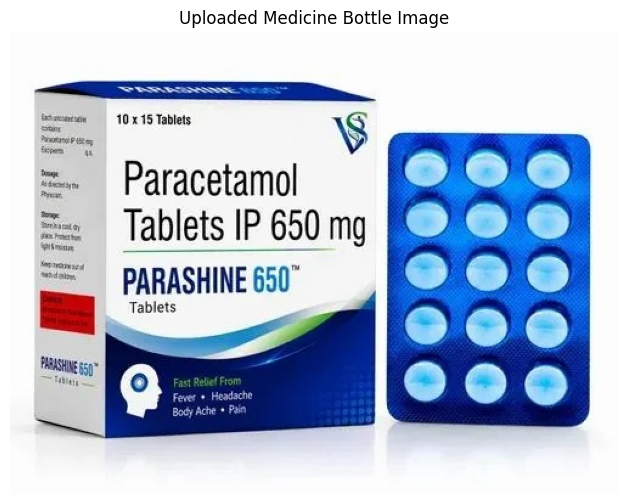

In [6]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to read image. Please upload JPG or PNG.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Uploaded Medicine Bottle Image")
plt.axis("off")
plt.show()

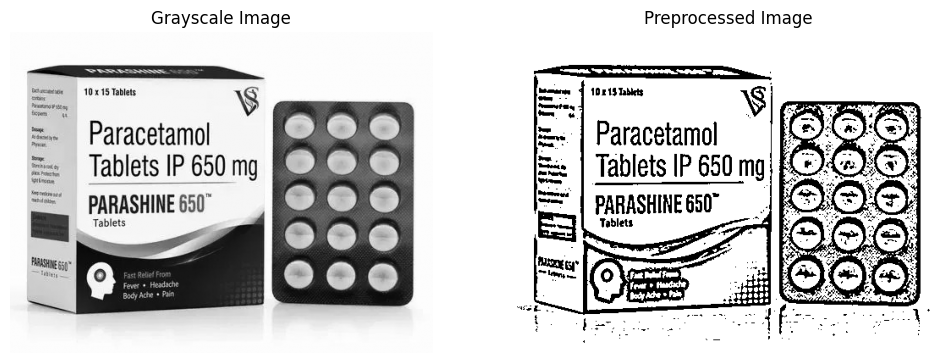

In [7]:
# Convert image to grayscale

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Remove noise

denoised = cv2.GaussianBlur(gray, (3, 3), 0)

# Improve contrast

processed = cv2.adaptiveThreshold(
    denoised,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed, cmap='gray')
plt.title("Preprocessed Image")
plt.axis("off")

plt.show()

In [8]:
results = reader.readtext(image)

extracted_text = []

for result in results:

    text = result[1]

    confidence = result[2]

    extracted_text.append(text)

    print("Detected Text:", text)

    print("Confidence:", round(confidence, 3))

    print("--------------------------")


full_text = " ".join(extracted_text)

print("\nCOMPLETE EXTRACTED TEXT:\n")

print(full_text)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Detected Text: 10 x 15 Tablets
Confidence: 0.904
--------------------------
Detected Text: Paracetamol
Confidence: 0.998
--------------------------
Detected Text: Tablets IP 650 mg
Confidence: 0.915
--------------------------
Detected Text: PARASHINE 650
Confidence: 0.999
--------------------------
Detected Text: Tablets
Confidence: 0.674
--------------------------
Detected Text: Fast Reliet Ftom
Confidence: 0.546
--------------------------
Detected Text: Ferc
Confidence: 0.037
--------------------------
Detected Text: Hcadachc
Confidence: 0.665
--------------------------
Detected Text: Booj Adie
Confidence: 0.041
--------------------------
Detected Text: Bnee"
Confidence: 0.032
--------------------------

COMPLETE EXTRACTED TEXT:

10 x 15 Tablets Paracetamol Tablets IP 650 mg PARASHINE 650 Tablets Fast Reliet Ftom Ferc Hcadachc Booj Adie Bnee"


In [9]:
def extract_medicine_information(text):

    lines = [
        line.strip()
        for line in text.split()
        if line.strip()
    ]

    # Medicine name: initial text candidates
    medicine_name = "Not confidently identified"

    medicine_keywords = [
        "tablet", "capsule", "syrup",
        "injection", "mg", "ml"
    ]

    for line in lines:

        if any(char.isalpha() for char in line):

            if not re.search(
                r'exp|expiry|mfg|manufact|batch|lot|mrp|dosage',
                line,
                re.IGNORECASE
            ):

                medicine_name = line
                break

    # Dosage extraction

    dosage_pattern = r'\b\d+(?:\.\d+)?\s?(?:mg|mcg|g|ml|iu|%)\b'

    dosage = re.findall(
        dosage_pattern,
        text,
        re.IGNORECASE
    )

    # Date extraction

    date_pattern = (
        r'\b(?:0?[1-9]|[12][0-9]|3[01])'
        r'[-/.](?:0?[1-9]|1[0-2])'
        r'[-/.](?:20)?\d{2}\b'
        r'|\b(?:0?[1-9]|1[0-2])'
        r'[-/.](?:20)?\d{2}\b'
    )

    dates = re.findall(date_pattern, text)

    # Expiry and manufacturing keyword detection

    expiry = "Not detected"

    manufacturing = "Not detected"

    expiry_match = re.search(
        r'(?:exp|expiry|use before|best before)\s*[:.-]?\s*'
        r'(' + date_pattern + r')',
        text,
        re.IGNORECASE
    )

    mfg_match = re.search(
        r'(?:mfg|manufactured|manufacturing)\s*[:.-]?\s*'
        r'(' + date_pattern + r')',
        text,
        re.IGNORECASE
    )

    if expiry_match:
        expiry = expiry_match.group(1)

    if mfg_match:
        manufacturing = mfg_match.group(1)

    return {
        "Medicine Name Candidate": medicine_name,
        "Dosage": ", ".join(set(dosage)) if dosage else "Not detected",
        "Manufacturing Date": manufacturing,
        "Expiry Date": expiry,
        "All Detected Dates": ", ".join(set(dates)) if dates else "None"
    }


medicine_info = extract_medicine_information(full_text)

for key, value in medicine_info.items():

    print(key, ":", value)

Medicine Name Candidate : x
Dosage : 650 mg
Manufacturing Date : Not detected
Expiry Date : Not detected
All Detected Dates : None


In [10]:
from datetime import datetime
import calendar

def check_expiry(expiry_text):

    if expiry_text == "Not detected":

        return "Expiry date not detected. Verify the packaging manually."

    formats = [
        "%d-%m-%Y",
        "%d/%m/%Y",
        "%d.%m.%Y",
        "%d-%m-%y",
        "%d/%m/%y",
        "%m-%Y",
        "%m/%Y",
        "%m-%y",
        "%m/%y"
    ]

    parsed_date = None

    for fmt in formats:

        try:

            parsed_date = datetime.strptime(
                expiry_text,
                fmt
            )

            if fmt in ["%m-%Y", "%m/%Y", "%m-%y", "%m/%y"]:

                last_day = calendar.monthrange(
                    parsed_date.year,
                    parsed_date.month
                )[1]

                parsed_date = parsed_date.replace(day=last_day)

            break

        except ValueError:
            continue

    if parsed_date is None:

        return "Expiry date format unclear. Manual verification required."

    today = datetime.today()

    if parsed_date.date() < today.date():

        return "EXPIRED – Do not use. Consult a pharmacist."

    else:

        return "Not past the detected expiry date. Verify the label and storage conditions."


expiry_status = check_expiry(
    medicine_info["Expiry Date"]
)

print("EXPIRY STATUS:", expiry_status)

EXPIRY STATUS: Expiry date not detected. Verify the packaging manually.


In [11]:
report = pd.DataFrame(
    medicine_info.items(),
    columns=["Parameter", "Extracted Information"]
)

display(report)

print("\nMEDICINE LABEL READING ASSISTANT")

print("----------------------------------")

print("Expiry Status:", expiry_status)

print("----------------------------------")

print("Important: Always verify medicine details with the original")
print("packaging or a qualified pharmacist before taking medication.")

,Parameter,Extracted Information
0,Medicine Name Candidate,x
1,Dosage,650 mg
2,Manufacturing Date,Not detected
3,Expiry Date,Not detected
4,All Detected Dates,None



MEDICINE LABEL READING ASSISTANT
----------------------------------
Expiry Status: Expiry date not detected. Verify the packaging manually.
----------------------------------
Important: Always verify medicine details with the original
packaging or a qualified pharmacist before taking medication.


In [8]:
!pip install -q deepface tf-keras

In [7]:
from deepface import DeepFace
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [9]:
!pip install deepface tf-keras

In [10]:
import os

os.environ["TF_USE_LEGACY_KERAS"] = "1"

import cv2
import numpy as np
import matplotlib.pyplot as plt

from deepface import DeepFace
from google.colab import files
from IPython.display import display

print("Emotion recognition libraries imported successfully!")

Emotion recognition libraries imported successfully!


Saving WhatsApp Image 2026-11-11 at 12.06.46 AM.jpeg to WhatsApp Image 2026-11-11 at 12.06.46 AM (1).jpeg


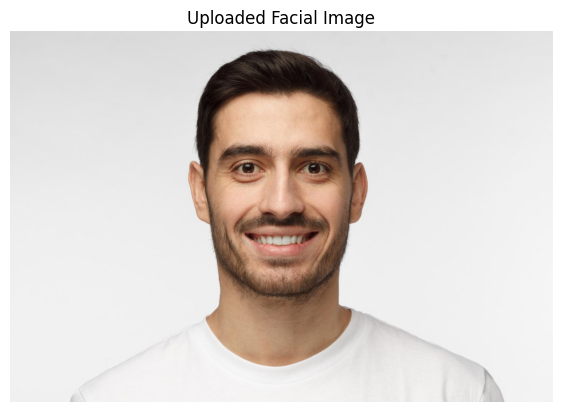

In [11]:
uploaded = files.upload()

face_image_path = list(uploaded.keys())[0]

face_image = cv2.imread(face_image_path)

if face_image is None:
    raise ValueError("Unable to read image. Upload a valid JPG or PNG.")

face_rgb = cv2.cvtColor(
    face_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(7, 6))

plt.imshow(face_rgb)

plt.title("Uploaded Facial Image")

plt.axis("off")

plt.show()

In [12]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

!pip install opencv-contrib-python-headless==4.11.0.86

Found existing installation: opencv-contrib-python-headless 4.11.0.86
Uninstalling opencv-contrib-python-headless-4.11.0.86:
  Successfully uninstalled opencv-contrib-python-headless-4.11.0.86
  Using cached opencv_contrib_python_headless-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_contrib_python_headless-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (56.1 MB)


In [13]:
import cv2

print("Version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

Version: 4.11.0
CascadeClassifier: True


In [14]:
from deepface import DeepFace
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [15]:
uploaded = files.upload()
face_image_path = list(uploaded.keys())[0]

Saving WhatsApp Image 2026-11-11 at 12.06.46 AM.jpeg to WhatsApp Image 2026-11-11 at 12.06.46 AM (2).jpeg


In [16]:
result = DeepFace.analyze(
    img_path=face_image_path,
    actions=['emotion'],
    detector_backend='opencv',
    enforce_detection=True,
    silent=True
)

print(result)

26-11-10 18:48:11 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 307MB/s]

[{'emotion': {'angry': np.float32(6.4216005e-07), 'disgust': np.float32(5.3101033e-15), 'fear': np.float32(9.512796e-08), 'happy': np.float32(97.84642), 'sad': np.float32(2.40772e-06), 'surprise': np.float32(0.016910488), 'neutral': np.float32(2.136669)}, 'dominant_emotion': 'happy', 'region': {'x': 509, 'y': 174, 'w': 576, 'h': 576, 'left_eye': (890, 403), 'right_eye': (695, 403)}, 'face_confidence': 0.88}]


In [17]:
emotions = result[0]['emotion']
dominant_emotion = result[0]['dominant_emotion']

print("FACIAL EXPRESSION ANALYSIS")
print("--------------------------")
print("Dominant Expression:", dominant_emotion.upper())

for emotion, score in emotions.items():
    print(f"{emotion.capitalize()}: {float(score):.2f}%")

FACIAL EXPRESSION ANALYSIS
--------------------------
Dominant Expression: HAPPY
Angry: 0.00%
Disgust: 0.00%
Fear: 0.00%
Happy: 97.85%
Sad: 0.00%
Surprise: 0.02%
Neutral: 2.14%


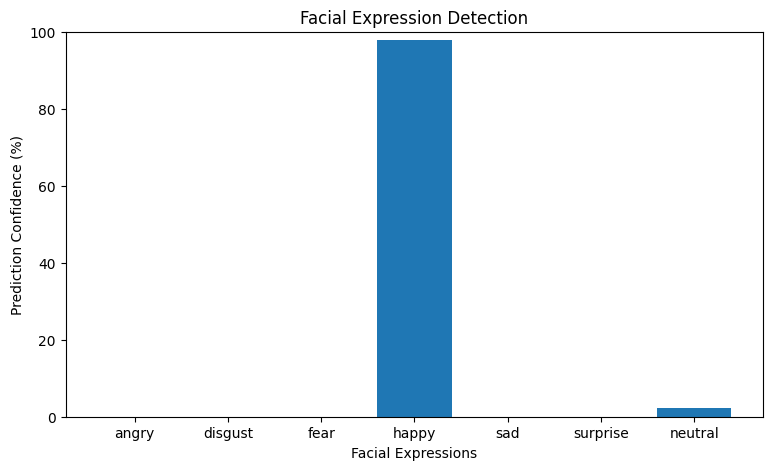

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(
    emotions.keys(),
    [float(score) for score in emotions.values()]
)

plt.title("Facial Expression Detection")
plt.xlabel("Facial Expressions")
plt.ylabel("Prediction Confidence (%)")
plt.ylim(0, 100)
plt.show()

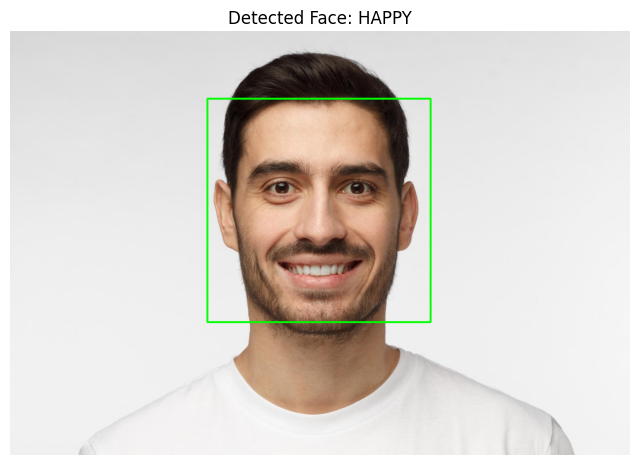

In [19]:
image = cv2.imread(face_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

region = result[0]['region']

x, y, w, h = region['x'], region['y'], region['w'], region['h']

cv2.rectangle(image, (x, y), (x+w, y+h), (0, 255, 0), 3)

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title("Detected Face: " + dominant_emotion.upper())
plt.axis("off")
plt.show()

In [20]:
def emotion_aware_assistant(emotion):

    responses = {
        'happy': "You appear to be showing a happy expression! Keep spreading positivity.",
        'sad': "You appear to be showing a sad expression. Take a moment to relax and care for yourself.",
        'angry': "You appear to be showing an angry expression. Take a deep breath and give yourself a moment.",
        'fear': "You appear to be showing a fearful expression. Try to stay calm and take things one step at a time.",
        'surprise': "You appear surprised! Something unexpected might have happened.",
        'disgust': "You appear to be showing an expression of disgust.",
        'neutral': "You appear to have a neutral facial expression."
    }

    return responses.get(emotion, "Unable to identify the expression.")

print("EMOTION-AWARE COGNITIVE ASSISTANT")
print("--------------------------------")
print("Detected Expression:", dominant_emotion.upper())
print("Assistant Response:", emotion_aware_assistant(dominant_emotion))

EMOTION-AWARE COGNITIVE ASSISTANT
--------------------------------
Detected Expression: HAPPY
Assistant Response: You appear to be showing a happy expression! Keep spreading positivity.


In [21]:
uploaded = files.upload()

for filename in uploaded.keys():

    new_result = DeepFace.analyze(
        img_path=filename,
        actions=['emotion'],
        detector_backend='opencv',
        enforce_detection=True,
        silent=True
    )

    new_emotion = new_result[0]['dominant_emotion']

    print("\nImage:", filename)
    print("Detected Expression:", new_emotion.upper())
    print("Assistant Response:", emotion_aware_assistant(new_emotion))

Saving WhatsApp Image 2026-11-11 at 12.21.32 AM.jpeg to WhatsApp Image 2026-11-11 at 12.21.32 AM.jpeg

Image: WhatsApp Image 2026-11-11 at 12.21.32 AM.jpeg
Detected Expression: FEAR
Assistant Response: You appear to be showing a fearful expression. Try to stay calm and take things one step at a time.


In [22]:
print("""
CONCLUSION:

The Emotion-Aware Cognitive Assistant was successfully implemented
using facial expression detection.

The system:
1. Accepts a facial image as input.
2. Detects the human face using OpenCV.
3. Uses the pretrained DeepFace model to classify facial expressions.
4. Identifies the dominant facial expression.
5. Generates a context-based response according to the detected expression.

The system demonstrates how computer vision and cognitive computing
can be integrated to create an emotion-aware assistant.
""")


CONCLUSION:

The Emotion-Aware Cognitive Assistant was successfully implemented
using facial expression detection.

The system:
1. Accepts a facial image as input.
2. Detects the human face using OpenCV.
3. Uses the pretrained DeepFace model to classify facial expressions.
4. Identifies the dominant facial expression.
5. Generates a context-based response according to the detected expression.

The system demonstrates how computer vision and cognitive computing
can be integrated to create an emotion-aware assistant.

